# Tarea 2 · Sección de cada fragmento (chunk)

**Persona 2 · Entrega 2 de RAG-CIDH.** Notebook `t2_secciones.ipynb`, que sigue el contrato de `clasificacion/README.md`.

**Problema.** Dado el texto de un fragmento de sentencia, predecir en qué sección está: Hechos, Prueba, Fondo, Reparaciones, Excepciones preliminares o Puntos resolutivos (multiclase).

**Para qué sirve.** En la Entrega 1, `buscar(..., seccion="Hechos")` solo ve los chunks cuya sección se detectó con los títulos del PDF. Las sentencias antiguas no tienen títulos y sus chunks quedan como «Sin sección», fuera de cualquier filtro. Si el clasificador acierta, esos chunks recuperan una sección y el filtro cubre más corpus.

### Mapa del notebook

| # | Bloque | Qué produce |
|---|---|---|
| 0 | Configuración | rutas, banderas, entorno (local o Colab) |
| 1 | Datos | los conjuntos del equipo, verificaciones y descriptivos |
| 2 | Embeddings e5 sin cabecera | **lo único pesado de GPU**; caché en disco |
| 3 | Marco de validación anidada | funciones que usan todos los modelos |
| 4 | Modelos lineales | línea base, Naive Bayes, regresión logística, SVM, e5 + regresión logística |
| 5 | Prueba temporal | entrenar hasta 2018, evaluar desde 2019 |
| 6 | RoBERTa-BNE (opcional) | afinado, si alcanza el tiempo |
| 7 | Análisis | F1 por clase, matriz de confusión, Hechos vs Fondo, errores |
| 8 | Aplicación a «Sin sección» | predicción, umbral de confianza, muestra de revisión manual |
| 9 | Efecto en `buscar()` | ¿mejora el filtro por sección? (consultas juzgadas B y C) |
| 10 | Salidas | tablas al repositorio y borrador de resultados para el artículo |

### Cómo ejecutarlo
- **Local (CPU):** define `CORTEIDH_BASE` (carpeta del proyecto con `procesado/`) y abre el notebook. Se puede correr todo menos el bloque 2, que en CPU tarda horas; si ya tienes el caché de embeddings (de Colab o Drive), el bloque 2 solo lo lee.
- **Colab (GPU):** el repositorio debe estar ya clonado en Colab (ver `clasificacion/README.md`; el notebook no usa git). El bloque 0 monta Drive e instala las librerías que falten. Corre primero el bloque 2 con GPU (T4 o mejor) y deja el caché en Drive.
- **Prueba rápida:** `MODO_PRUEBA = True` usa una fracción de los casos para comprobar que todo corre.

## 0. Configuración

**Qué hace esta celda.** Detecta si estás en Colab o en local, deja `clasificacion/` en el `sys.path` para importar `comun.py` (constantes, particiones y métricas del equipo) y define las banderas del notebook.

- En Colab, monta Drive e instala las librerías que falten. El repositorio **ya tiene que estar clonado** (variable `REPO_DIR`): el notebook no ejecuta ningún comando de git.
- En local, `CORTEIDH_BASE` **debe estar definida antes de abrir el notebook**, porque `comun.py` la lee al importarse.
- Las banderas están al principio para que no haya que buscarlas más abajo.

In [1]:
import os, sys, json, time, subprocess, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# ── Banderas ──────────────────────────────────────────────────
REPO_DIR        = "/content/RAG-CIDH"  # solo Colab: carpeta donde clonaste el repositorio
MODO_PRUEBA     = False                # True: usa ~8 % de los casos para comprobar que todo corre
AFINAR_ROBERTA  = False                # True: corre el bloque 6 (necesita GPU y de 1 a 2 h por partición)
FOLDS_ROBERTA   = [0]                  # particiones con RoBERTa; todas = [0, 1, 2, 3, 4]
N_JOBS          = min(4, os.cpu_count()) # procesos de GridSearchCV. Más de 4 agota la memoria en Windows: cada proceso carga torch
N_INTERNO       = 3                    # particiones de la validación interna (hiperparámetros)
PREC_OBJETIVO   = 0.90                 # precisión mínima para aceptar una etiqueta predicha en «Sin sección»

try:
    import google.colab                                   # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO = Path(os.environ.get("REPO_DIR", REPO_DIR))
    assert (REPO / "clasificacion" / "comun.py").exists(), f"No encuentro el repositorio en {REPO}: clónalo antes (ver clasificacion/README.md)."
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn", "pyarrow", "seaborn",
                    "sentence-transformers", "transformers"], check=True)
    DIR_CLASIF = REPO / "clasificacion"
else:
    cwd = Path.cwd()
    candidatas = [cwd, cwd / "clasificacion", *cwd.parents, *(p / "clasificacion" for p in cwd.parents)]
    DIR_CLASIF = next((c for c in candidatas if (c / "comun.py").exists()), None)
    assert DIR_CLASIF, "No encuentro clasificacion/comun.py: abre el notebook dentro del repositorio."
    assert "CORTEIDH_BASE" in os.environ, "Define CORTEIDH_BASE (carpeta del proyecto) antes de abrir el notebook."

sys.path.insert(0, str(DIR_CLASIF))
from comun import *            # SEMILLA, N_PARTICIONES, CLASES_SECCION, cargar_*, métricas, guardar_tabla...
import comun

DIR_REPO   = DIR_CLASIF.parent
DIR_FIG    = BASE_DIR / "procesado" / "figuras"
DIR_FIG.mkdir(parents=True, exist_ok=True)
assert DIR_DATOS.exists(), f"No existe {DIR_DATOS}: corre clasificacion/construir_conjuntos.py o descarga los .parquet de Drive."

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")

def guardar_fig(nombre):
    # Figuras con prefijo «c» (contrato). La Persona 2 usa la serie c2x para no chocar con las otras.
    plt.tight_layout()
    plt.savefig(DIR_FIG / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Colab           :", EN_COLAB)
print("Repositorio     :", DIR_REPO)
print("BASE_DIR        :", BASE_DIR)
print("Conjuntos       :", DIR_DATOS)
print("Semilla / folds :", SEMILLA, "/", N_PARTICIONES)

Colab           : False
Repositorio     : C:\Users\USER\Desktop\proyectoPLN
BASE_DIR        : C:\Users\USER\Desktop\proyectoPLN
Conjuntos       : C:\Users\USER\Desktop\proyectoPLN\procesado\clasificacion
Semilla / folds : 42 / 5


## 1. Datos del equipo

**Qué hace esta celda.** Carga, con las funciones de `comun.py`, los dos conjuntos de la tarea:

- `sec`: 59.184 chunks etiquetados con su `seccion_canonica`, de 422 casos. Ya excluye los casi duplicados y los chunks de menos de 20 palabras. Trae la columna `particion` (0–4), que sale de `StratifiedGroupKFold` por caso.
- `sin`: 1.718 chunks «Sin sección» sin etiqueta, el conjunto de aplicación.

Se cumple el contrato:

1. **Texto de entrada:** solo `texto` (o `texto_normalizado`, que son sus lemas). Nunca `texto_con_contexto`, porque su cabecera trae el nombre de la sección y haría trampa.
2. **Particiones:** un caso nunca está en entrenamiento y prueba a la vez. Se comprueba con `assert`.

Si `MODO_PRUEBA` está activo, se toma una fracción de los casos **respetando la partición de cada uno**, para no cambiar las particiones oficiales.

In [2]:
sec, y = cargar_secciones()
sin = cargar_sin_seccion()

if MODO_PRUEBA:
    rng = np.random.default_rng(SEMILLA)
    casos = sec.drop_duplicates("caso_id")[["caso_id", "particion"]]
    elegidos = pd.concat([g.sample(frac=0.08, random_state=SEMILLA) for _, g in casos.groupby("particion")])
    sec = sec[sec["caso_id"].isin(elegidos["caso_id"])].reset_index(drop=True)
    y = sec["seccion_canonica"].to_numpy()
    sin = sin.sample(min(len(sin), 200), random_state=SEMILLA).reset_index(drop=True)
    print(f"⚠ MODO_PRUEBA: {sec['caso_id'].nunique()} casos, {len(sec)} chunks. No usar para reportar resultados.")

sec["texto_normalizado"] = sec["texto_normalizado"].fillna("")
sin["texto_normalizado"] = sin["texto_normalizado"].fillna("")
grupos = sec["caso_id"].to_numpy()

# ── Verificaciones del contrato ──
assert set(y) == set(CLASES_SECCION)
assert sec.groupby("caso_id")["particion"].nunique().max() == 1, "un caso aparece en dos particiones"
assert "texto_con_contexto" not in sec.columns
assert not sec["texto"].str.contains(r"\s·\s(?:párrs?\.|puntos)\s\d", regex=True).any(), "hay cabeceras dentro del texto"
assert sec["chunk_id"].is_unique and not set(sec["chunk_id"]) & set(sin["chunk_id"])

print(f"Etiquetados : {len(sec):,} chunks de {sec['caso_id'].nunique()} casos".replace(",", "."))
print(f"Sin sección : {len(sin):,} chunks de {sin['caso_id'].nunique()} casos".replace(",", "."))
display(pd.DataFrame({"chunks": sec["seccion_canonica"].value_counts(),
                      "%": (100 * sec["seccion_canonica"].value_counts(normalize=True)).round(1),
                      "casos": sec.groupby("seccion_canonica")["caso_id"].nunique(),
                      "palabras (mediana)": sec.groupby("seccion_canonica")["num_palabras"].median()}).loc[CLASES_SECCION])

Etiquetados : 59.184 chunks de 422 casos
Sin sección : 1.718 chunks de 38 casos


,chunks,%,casos,palabras (mediana)
seccion_canonica,,,,
Hechos,10144,17.1,345,204.0
Prueba,4922,8.3,387,223.0
Fondo,26669,45.1,375,189.0
Reparaciones,11913,20.1,379,195.0
Excepciones preliminares,3375,5.7,225,190.0
Puntos resolutivos,2161,3.7,408,207.0


**Descriptivos.** Esta celda dibuja dos cosas que condicionan el resto del trabajo:

- **Desbalance de clases:** si Fondo domina, la exactitud engaña. Por eso la métrica principal es el **F1 macro** y los modelos usan `class_weight="balanced"`.
- **Época de cada clase y de «Sin sección»:** el conjunto de aplicación son sentencias antiguas, con otro estilo que las de entrenamiento. Si las dos distribuciones son muy distintas, el desempeño medido en validación será optimista para ese conjunto. Esto se retoma en el bloque 8.

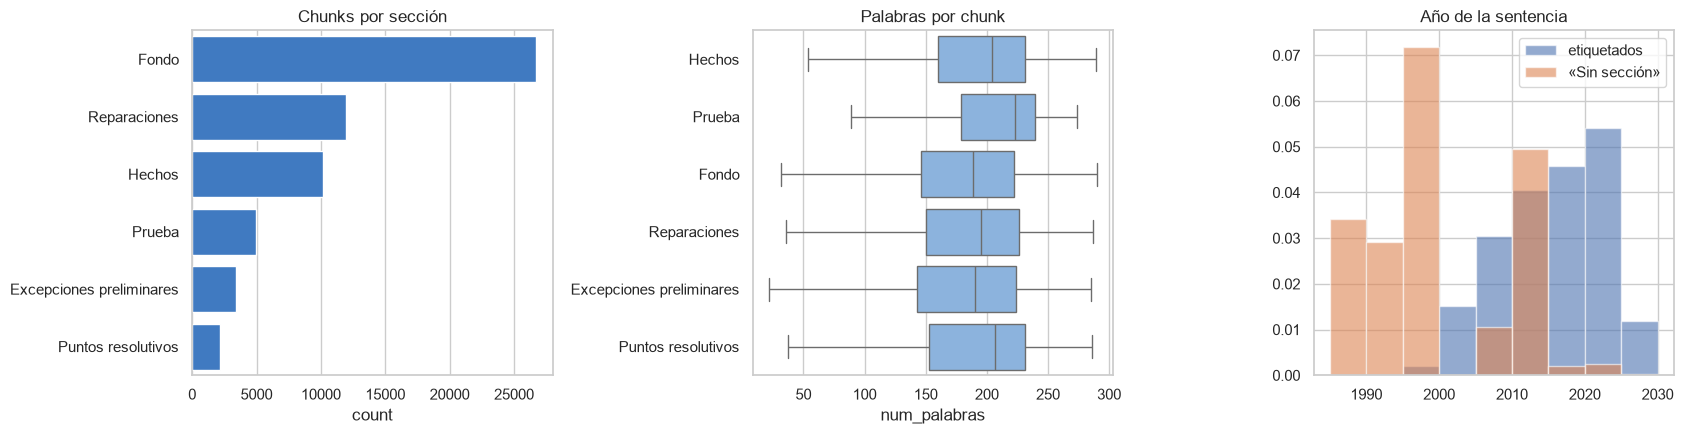

Mediana de año — etiquetados: 2016.0 · sin sección: 1996.0


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
orden = sec["seccion_canonica"].value_counts().index
sns.countplot(data=sec, y="seccion_canonica", order=orden, color="#2a78d6", ax=ax[0])
ax[0].set_title("Chunks por sección"); ax[0].set_ylabel("")
sns.boxplot(data=sec, y="seccion_canonica", x="num_palabras", order=CLASES_SECCION, color="#7fb3ea", ax=ax[1], showfliers=False)
ax[1].set_title("Palabras por chunk"); ax[1].set_ylabel("")
bins = np.arange(1985, 2031, 5)
ax[2].hist(sec["anio"].dropna(), bins=bins, alpha=.6, density=True, label="etiquetados")
ax[2].hist(sin["anio"].dropna(), bins=bins, alpha=.6, density=True, label="«Sin sección»")
ax[2].set_title("Año de la sentencia"); ax[2].legend()
guardar_fig("c21_t2_descriptivos")
print("Mediana de año — etiquetados:", sec["anio"].median(), "· sin sección:", sin["anio"].median())

## 2. Embeddings e5 **sin cabecera** (la parte pesada de GPU)

**Por qué hay que recalcularlos.** Los embeddings de la Entrega 1 se calcularon sobre `texto_con_contexto`, que empieza con una cabecera como *«Caso X vs. Y (2011) · Hechos · párrs. 12–15»*. Esa cabecera **contiene la etiqueta que queremos predecir**. Un clasificador entrenado sobre esos vectores aprendería a leer la cabecera y no el texto. Aquí se calculan sobre `texto` solo, con el prefijo `passage: ` que pide e5.

**Cómo funciona la celda.**
- `cargar_e5()` carga `intfloat/multilingual-e5-base` (fp16 en GPU, ventana de 512 tokens, igual que la Entrega 1).
- `asegurar_embeddings(df)` devuelve los vectores de los chunks de `df` y **calcula solo los que no están** en el caché. Guarda cada 4.096 chunks, así que si Colab se desconecta no se pierde todo: al volver a correr la celda continúa donde quedó.
- El caché vive en `procesado/clasificacion/` (Drive) como `embeddings_t2_e5_sin_cabecera.npy` (float16) más un `.json` con los `chunk_id` en el mismo orden. Se busca por `chunk_id`, no por posición, así que no depende del orden de `sec`.
- Se calculan los 59.184 + 1.718 chunks. Referencia medida en la Entrega 1 (`CAMBIOS.md`, 8.1): unos 150 s para 79.799 chunks en una RTX 4070. Aquí debe tardar un par de minutos en esa tarjeta; en una T4 de Colab espera de 5 a 10 minutos (estimación, no medida).

In [4]:
MODELO_E5 = "intfloat/multilingual-e5-base"
DIM_E5 = 768
RUTA_EMB = DIR_DATOS / "embeddings_t2_e5_sin_cabecera.npy"
RUTA_IDS = DIR_DATOS / "embeddings_t2_e5_sin_cabecera_ids.json"
_e5 = {}

def cargar_e5():
    # Carga perezosa: si el caché está completo, nunca se carga el modelo.
    if "m" not in _e5:
        import torch
        from sentence_transformers import SentenceTransformer
        dev = "cuda" if torch.cuda.is_available() else "cpu"
        m = SentenceTransformer(MODELO_E5, device=dev)
        if dev == "cuda":
            m = m.half()
        m.max_seq_length = 512
        _e5.update(m=m, dev=dev)
        print("e5 cargado en", dev)
        if dev == "cpu":
            print("⚠ Sin GPU: calcular decenas de miles de chunks puede tardar horas. Usa Colab.")
    return _e5["m"]

def leer_cache():
    if RUTA_EMB.exists() and RUTA_IDS.exists():
        ids, E = json.loads(RUTA_IDS.read_text()), np.load(RUTA_EMB)
        assert len(ids) == len(E), "caché corrupto: ids y matriz no coinciden; bórralo"
        return ids, E
    return [], np.zeros((0, DIM_E5), np.float16)

def escribir_cache(ids, E):
    np.save(RUTA_EMB, E)
    RUTA_IDS.write_text(json.dumps(ids))

def asegurar_embeddings(df, lote_guardado=4096, batch=64):
    # Devuelve (len(df), 768) float32, alineada con df, calculando solo lo que falta.
    ids, E = leer_cache()
    falta = df[~df["chunk_id"].isin(set(ids))]
    if len(falta):
        print(f"Calculando {len(falta):,} embeddings (en caché: {len(ids):,})".replace(",", "."))
        modelo = cargar_e5()
        import torch
        for ini in range(0, len(falta), lote_guardado):
            bloque = falta.iloc[ini:ini + lote_guardado]
            with torch.inference_mode():
                nuevo = modelo.encode([f"passage: {t}" for t in bloque["texto"]], batch_size=batch,
                                      normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
            ids += bloque["chunk_id"].tolist()
            E = np.vstack([E, nuevo.astype(np.float16)])
            escribir_cache(ids, E)
            print(f"  guardado: {len(ids):,} chunks".replace(",", "."))
    pos = {c: i for i, c in enumerate(ids)}
    return E[[pos[c] for c in df["chunk_id"]]].astype(np.float32)

t0 = time.time()
E_sec = asegurar_embeddings(sec)
print("Embeddings de los chunks etiquetados:", E_sec.shape, f"· {time.time() - t0:.0f} s")
assert np.isfinite(E_sec).all() and abs(np.linalg.norm(E_sec, axis=1).mean() - 1) < 0.01   # normalizados

Embeddings de los chunks etiquetados: (59184, 768) · 0 s


**Diagnóstico opcional: ¿de verdad la cabecera hacía trampa?** Esta celda lo mide, y su resultado sirve para justificar el recálculo en el artículo. Solo corre si existen los archivos de la Entrega 1 (`chunks.parquet` y `embeddings.npy`, que tienen cabecera).

Entrena la **misma** regresión logística (C = 10, sin buscar hiperparámetros) en la partición 0, una vez con los embeddings con cabecera y otra con los de esta sección, y compara el F1 macro. Si el de con cabecera es mucho más alto, es porque el modelo lee la etiqueta en la cabecera. Es una demostración sobre una sola partición, no un resultado del trabajo.

In [5]:
ruta_ch = BASE_DIR / "procesado/caracteristicas/chunks.parquet"
ruta_e1 = BASE_DIR / "procesado/caracteristicas/embeddings.npy"
if ruta_ch.exists() and ruta_e1.exists():
    from sklearn.linear_model import LogisticRegression
    ch_ids = pd.read_parquet(ruta_ch, columns=["chunk_id"])["chunk_id"]
    E1 = np.load(ruta_e1, mmap_mode="r")
    pos1 = pd.Series(np.arange(len(ch_ids)), index=ch_ids)
    E_cab = np.asarray(E1[pos1.loc[sec["chunk_id"]].to_numpy()], dtype=np.float32)
    k, ent, pru = next(iterar_particiones(sec))
    res = {}
    for nombre, X in [("con cabecera (Entrega 1)", E_cab), ("sin cabecera (esta tarea)", E_sec)]:
        lr = LogisticRegression(C=10, max_iter=500, class_weight="balanced").fit(X[ent], y[ent])
        res[nombre] = metricas_multiclase(y[pru], lr.predict(X[pru]))
    display(pd.DataFrame(res).T.round(3))
else:
    print("No están chunks.parquet / embeddings.npy de la Entrega 1: se omite el diagnóstico.")

,exactitud,exactitud_balanceada,f1_macro,f1_ponderado
con cabecera (Entrega 1),0.920,0.937,0.923,0.922
sin cabecera (esta tarea),0.806,0.850,0.803,0.808


## 3. Marco de validación anidada

**Qué define esta celda.** Las piezas que usan todos los modelos, para que la comparación sea justa:

- **Validación externa:** las 5 particiones oficiales (`iterar_particiones`), por caso. En cada una, el modelo se entrena con 4 y se evalúa con la restante.
- **Validación interna:** dentro del entrenamiento de cada partición, `GridSearchCV` elige los hiperparámetros con `StratifiedGroupKFold(3)` **agrupado por caso** y mide F1 macro. La partición de prueba no se mira nunca para elegir nada.
- **TF-IDF dentro del `Pipeline`:** el vocabulario y los IDF se reajustan en cada entrenamiento, como exige el contrato (el `tfidf_vectorizer.joblib` de la Entrega 1 se ajustó con todo el corpus y no sirve).
- **Salidas por modelo y partición:** una fila `{"modelo", "particion", métricas…}` con las métricas de `comun.metricas_multiclase`, más el F1 de cada clase. También se guardan las predicciones de prueba y su confianza (predicciones fuera de muestra, o OOF), que se usan para la matriz de confusión y para elegir el umbral del bloque 8.
- **Confianza:** la probabilidad máxima si el modelo la da. Para SVM se usa el softmax de los márgenes, que **no está calibrado**: sirve para ordenar y elegir un umbral, no como probabilidad real.

In [6]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix

def _sub(X, idx):
    return X.iloc[idx] if hasattr(X, "iloc") else X[idx]

def ajustar(construir, rejilla, X_tr, y_tr, g_tr):
    # Ajusta un modelo. Con rejilla: validación interna agrupada por caso (nunca ve la partición de prueba).
    est = construir()
    if not rejilla:
        return est.fit(X_tr, y_tr), {}
    cv = StratifiedGroupKFold(N_INTERNO, shuffle=True, random_state=SEMILLA)
    gs = GridSearchCV(est, rejilla, cv=cv, scoring="f1_macro", n_jobs=N_JOBS, refit=True)
    gs.fit(X_tr, y_tr, groups=g_tr)
    return gs.best_estimator_, gs.best_params_

def puntajes(modelo, X):
    # Matriz (n, clases) de probabilidades o, si el modelo no las da, softmax de los márgenes.
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)
    d = modelo.decision_function(X)
    e = np.exp(d - d.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)

def predecir(modelo, X):
    s = puntajes(modelo, X)
    return modelo.classes_[s.argmax(1)], s.max(1)

def fila_metricas(nombre, particion, y_real, y_pred):
    f1c = f1_score(y_real, y_pred, labels=CLASES_SECCION, average=None, zero_division=0)
    return {"modelo": nombre, "particion": particion, **metricas_multiclase(y_real, y_pred),
            **{f"f1_{c}": v for c, v in zip(CLASES_SECCION, f1c)}}

def validacion_externa(nombre, spec, X):
    # 5 particiones oficiales. Devuelve filas de métricas, predicciones OOF, confianza y mejores hiperparámetros.
    filas, oof_pred, oof_conf, params = [], np.empty(len(sec), dtype=object), np.zeros(len(sec)), []
    for k, ent, pru in iterar_particiones(sec):
        t0 = time.time()
        modelo, p = ajustar(spec["construir"], spec["rejilla"], _sub(X, ent), y[ent], grupos[ent])
        pred, conf = predecir(modelo, _sub(X, pru))
        oof_pred[pru], oof_conf[pru] = pred, conf
        filas.append(fila_metricas(nombre, k, y[pru], pred)); params.append(p)
        print(f"  {nombre:<14} partición {k}: F1 macro {filas[-1]['f1_macro']:.3f} · exactitud {filas[-1]['exactitud']:.3f}"
              f" · {time.time() - t0:.0f} s · {p}")
    return filas, oof_pred, oof_conf, params

## 4. Modelos lineales

**Qué define esta celda.** El diccionario `MODELOS` con cada modelo, su rejilla de hiperparámetros y qué entrada usa (`lemas`, `texto` o `e5`):

| Modelo | Entrada | Hiperparámetros que se buscan |
|---|---|---|
| `base_mayoritaria` | – | – (siempre predice Fondo, la clase más frecuente) |
| `base_estratificada` | – | – (predice al azar según la frecuencia de cada clase) |
| `tfidf_nb` | lemas | `alpha` de Complement Naive Bayes |
| `tfidf_lr` | lemas | `C` de la regresión logística |
| `tfidf_lr_texto` | texto sin lematizar | ablación: ¿ayuda la lematización? |
| `tfidf_svm` | lemas | `C` del SVM lineal |
| `e5_lr` | embeddings e5 sin cabecera | `C` de la regresión logística |
| `e5_svm` | embeddings e5 sin cabecera | `C` del SVM lineal |

**Detalles de diseño:**
- TF-IDF con 1–2-gramas, `min_df=3`, `max_df=0.5`, `sublinear_tf` y máximo de 100.000 características: el mismo tipo de ajuste de la Entrega 1, pero dentro del `Pipeline`.
- `class_weight="balanced"` en regresión logística y SVM, porque la métrica principal es el F1 macro. Complement NB ya corrige el desbalance por diseño.
- La línea base no usa el texto: cualquier modelo útil tiene que superarla en F1 macro.
- Para correr solo algunos modelos, edita `A_CORRER`.

Esta celda **solo define**; la siguiente los ejecuta.

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.5, sublinear_tf=True, max_features=100_000)

MODELOS = {
    "base_mayoritaria":   dict(entrada="lemas", rejilla=None,
                               construir=lambda: DummyClassifier(strategy="most_frequent")),
    "base_estratificada": dict(entrada="lemas", rejilla=None,
                               construir=lambda: DummyClassifier(strategy="stratified", random_state=SEMILLA)),
    "tfidf_nb":     dict(entrada="lemas", rejilla={"clf__alpha": [0.1, 0.3, 1.0]},
                         construir=lambda: Pipeline([("tfidf", tfidf()), ("clf", ComplementNB())])),
    "tfidf_lr":     dict(entrada="lemas", rejilla={"clf__C": [1, 10]},
                         construir=lambda: Pipeline([("tfidf", tfidf()),
                                                     ("clf", LogisticRegression(max_iter=200, class_weight="balanced"))])),
    "tfidf_lr_texto": dict(entrada="texto", rejilla={"clf__C": [1, 10]},
                         construir=lambda: Pipeline([("tfidf", tfidf()),
                                                     ("clf", LogisticRegression(max_iter=200, class_weight="balanced"))])),
    "tfidf_svm":    dict(entrada="lemas", rejilla={"clf__C": [0.1, 1]},
                         construir=lambda: Pipeline([("tfidf", tfidf()),
                                                     ("clf", LinearSVC(class_weight="balanced"))])),
    "e5_lr":        dict(entrada="e5", rejilla={"C": [1, 10, 100]},
                         construir=lambda: LogisticRegression(max_iter=1000, class_weight="balanced")),
    "e5_svm":       dict(entrada="e5", rejilla={"C": [0.1, 1, 10]},
                         construir=lambda: LinearSVC(class_weight="balanced")),
}
ENTRADAS = {"lemas": sec["texto_normalizado"], "texto": sec["texto"], "e5": E_sec}
A_CORRER = list(MODELOS)
print("Modelos definidos:", A_CORRER)

Modelos definidos: ['base_mayoritaria', 'base_estratificada', 'tfidf_nb', 'tfidf_lr', 'tfidf_lr_texto', 'tfidf_svm', 'e5_lr', 'e5_svm']


### Ejecución de la validación anidada

**Qué hace esta celda.** Recorre `A_CORRER` y llama a `validacion_externa` para cada modelo. Imprime el F1 macro y la exactitud de cada partición, además de los hiperparámetros elegidos dentro de cada entrenamiento (que pueden variar de una partición a otra, y eso es normal).

Al terminar guarda con `guardar_tabla`:
- `t2_cv_por_particion.csv`: una fila por modelo y partición;
- `t2_resumen_modelos.csv`: media y desviación por modelo;
- `t2_predicciones_oof.csv`: la predicción de prueba y la confianza de cada chunk y modelo.

**Tiempo.** Es la celda más lenta después de los embeddings, porque cada modelo con TF-IDF ajusta el vocabulario una vez por cada partición y combinación de hiperparámetros. Con las 59 mil filas, calcula decenas de minutos (estimación; no medida), y más con 2 núcleos. Si hace falta, ejecuta primero con `MODO_PRUEBA`.

In [8]:
filas_cv, oof, oof_conf, mejores_params = [], {}, {}, {}
t_total = time.time()
for nombre in A_CORRER:
    spec = MODELOS[nombre]
    print(f"\n▶ {nombre}")
    f, oof[nombre], oof_conf[nombre], mejores_params[nombre] = validacion_externa(nombre, spec, ENTRADAS[spec["entrada"]])
    filas_cv += f
print(f"\nTiempo total: {(time.time() - t_total) / 60:.1f} min")

tabla_cv = pd.DataFrame(filas_cv)
guardar_tabla(tabla_cv.set_index("modelo"), "t2_cv_por_particion")
resumen = resumir(filas_cv)
guardar_tabla(resumen, "t2_resumen_modelos")
pd.DataFrame({"chunk_id": sec["chunk_id"], "y": y, "caso_id": grupos, "particion": sec["particion"],
              **{f"pred_{m}": oof[m] for m in oof}, **{f"conf_{m}": oof_conf[m] for m in oof}}
             ).to_csv(DIR_RESULTADOS / "t2_predicciones_oof.csv", index=False)

principales = ["exactitud", "exactitud_balanceada", "f1_macro", "f1_ponderado"]
display(resumen[principales].sort_values(("f1_macro", "mean"), ascending=False))


▶ base_mayoritaria
  base_mayoritaria partición 0: F1 macro 0.104 · exactitud 0.452 · 0 s · {}


  base_mayoritaria partición 1: F1 macro 0.103 · exactitud 0.448 · 0 s · {}
  base_mayoritaria partición 2: F1 macro 0.104 · exactitud 0.454 · 0 s · {}


  base_mayoritaria partición 3: F1 macro 0.104 · exactitud 0.451 · 0 s · {}
  base_mayoritaria partición 4: F1 macro 0.103 · exactitud 0.448 · 0 s · {}

▶ base_estratificada


  base_estratificada partición 0: F1 macro 0.165 · exactitud 0.286 · 0 s · {}
  base_estratificada partición 1: F1 macro 0.167 · exactitud 0.282 · 0 s · {}


  base_estratificada partición 2: F1 macro 0.168 · exactitud 0.288 · 0 s · {}
  base_estratificada partición 3: F1 macro 0.167 · exactitud 0.288 · 0 s · {}
  base_estratificada partición 4: F1 macro 0.167 · exactitud 0.281 · 0 s · {}

▶ tfidf_nb


  tfidf_nb       partición 0: F1 macro 0.810 · exactitud 0.811 · 32 s · {'clf__alpha': 0.1}


... (26 outputs left out)

  e5_svm         partición 2: F1 macro 0.840 · exactitud 0.838 · 102 s · {'C': 10}


  e5_svm         partición 3: F1 macro 0.856 · exactitud 0.856 · 84 s · {'C': 10}


  e5_svm         partición 4: F1 macro 0.840 · exactitud 0.833 · 86 s · {'C': 10}

Tiempo total: 26.5 min


exactitud         exactitud_balanceada         f1_macro  \
                        mean     std                 mean     std     mean   
modelo                                                                       
tfidf_lr_texto        0.8698  0.0106               0.8664  0.0225   0.8722   
tfidf_svm             0.8541  0.0102               0.8470  0.0218   0.8554   
tfidf_lr              0.8525  0.0122               0.8502  0.0233   0.8546   
e5_svm                0.8348  0.0136               0.8500  0.0231   0.8341   
e5_lr                 0.8152  0.0139               0.8535  0.0217   0.8137   
tfidf_nb              0.8115  0.0123               0.7871  0.0216   0.8046   
base_estratificada    0.2850  0.0034               0.1667  0.0008   0.1667   
base_mayoritaria      0.4506  0.0028               0.1667  0.0000   0.1035   

                           f1_ponderado          
                       std         mean     std  
modelo                                           
tfidf_lr_texto      0.0175       0.8710  0.0104  
tfidf_svm           0.0176       0.8552  0.0098  
tfidf_lr            0.0193       0.8540  0.0118  
e5_svm              0.0179       0.8364  0.0133  
e5_lr               0.0172       0.8176  0.0135  
tfidf_nb            0.0175       0.8141  0.0116  
base_estratificada  0.0008       0.2844  0.0038  
base_mayoritaria    0.0004       0.2799  0.0029

**Comparación de modelos.** El gráfico muestra la media del F1 macro con su desviación entre particiones. Las barras de error son la variabilidad entre particiones de **casos distintos**, y es una medida más honesta que una sola partición aleatoria. Con 5 particiones, diferencias menores que una desviación estándar no deben presentarse como ganancias.

Se marca el mejor modelo (`mejor`), que usan los bloques 5, 7 y 8. Se elige **solo entre los modelos con texto** (la línea base no cuenta) y por F1 macro medio.

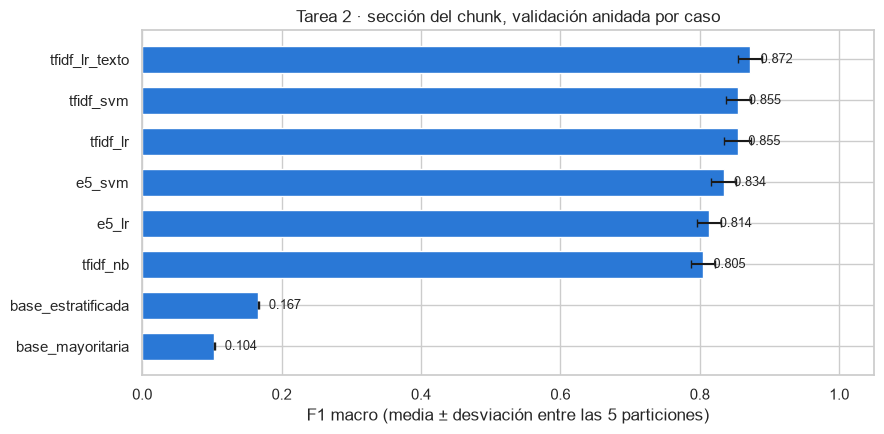

Mejor modelo por F1 macro: tfidf_lr_texto · [{'clf__C': 10}, {'clf__C': 10}, {'clf__C': 10}, {'clf__C': 10}, {'clf__C': 10}]


In [9]:
medias = tabla_cv.groupby("modelo")[["f1_macro", "exactitud"]].agg(["mean", "std"])
orden_m = medias[("f1_macro", "mean")].sort_values().index
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(orden_m, medias.loc[orden_m, ("f1_macro", "mean")], xerr=medias.loc[orden_m, ("f1_macro", "std")],
        color="#2a78d6", height=0.65, capsize=3)
for i, m in enumerate(orden_m):
    ax.text(medias.loc[m, ("f1_macro", "mean")] + 0.015, i, f"{medias.loc[m, ('f1_macro', 'mean')]:.3f}", va="center", fontsize=9)
ax.set_xlabel("F1 macro (media ± desviación entre las 5 particiones)"); ax.set_xlim(0, 1.05)
ax.set_title("Tarea 2 · sección del chunk, validación anidada por caso")
guardar_fig("c22_t2_comparacion_modelos")

con_texto = [m for m in A_CORRER if not m.startswith("base_")]
mejor = medias.loc[con_texto, ("f1_macro", "mean")].idxmax()
print("Mejor modelo por F1 macro:", mejor, "·", mejores_params[mejor])

## 5. Prueba temporal

**Qué hace esta celda.** Complementa la validación por casos con una pregunta más cercana al uso real: *¿funciona con sentencias posteriores a las que vio el modelo?* Entrena con los chunks de sentencias hasta 2018 y evalúa con los de 2019 en adelante (`particion_temporal`, `ANIO_CORTE` del contrato). Los hiperparámetros se eligen con la misma validación interna, dentro del entrenamiento.

**Cuidado.** Un mismo caso puede tener sentencias en años distintos (por ejemplo, fondo y reparaciones). Para que un caso no quede en los dos lados, **se sacan de la prueba los chunks de casos que también están en el entrenamiento**; la celda imprime cuántos se pierden.

In [10]:
ent_t, pru_t = particion_temporal(sec)
casos_ent = set(grupos[ent_t])
pru_t_lim = np.array([i for i in pru_t if grupos[i] not in casos_ent])
print(f"Entrenamiento hasta {ANIO_CORTE}: {len(ent_t):,} chunks · prueba: {len(pru_t_lim):,} "
      f"(se quitaron {len(pru_t) - len(pru_t_lim):,} de casos que también están en el entrenamiento)".replace(",", "."))

filas_temp, oof_temp = [], {}
for nombre in A_CORRER:
    spec = MODELOS[nombre]; X = ENTRADAS[spec["entrada"]]
    t0 = time.time()
    modelo, p = ajustar(spec["construir"], spec["rejilla"], _sub(X, ent_t), y[ent_t], grupos[ent_t])
    pred, conf = predecir(modelo, _sub(X, pru_t_lim))
    oof_temp[nombre] = (pred, conf)
    filas_temp.append(fila_metricas(nombre, "temporal", y[pru_t_lim], pred))
    print(f"  {nombre:<20} F1 macro {filas_temp[-1]['f1_macro']:.3f} · {time.time() - t0:.0f} s · {p}")

tabla_temp = pd.DataFrame(filas_temp).set_index("modelo")
guardar_tabla(tabla_temp, "t2_prueba_temporal")
comp = pd.DataFrame({"F1 macro CV por casos": tabla_cv.groupby("modelo")["f1_macro"].mean(),
                     "F1 macro temporal": tabla_temp["f1_macro"]}).round(3)
display(comp.sort_values("F1 macro temporal", ascending=False))

Entrenamiento hasta 2018: 37.274 chunks · prueba: 21.745 (se quitaron 8 de casos que también están en el entrenamiento)
  base_mayoritaria     F1 macro 0.112 · 0 s · {}


  base_estratificada   F1 macro 0.160 · 0 s · {}


  tfidf_nb             F1 macro 0.837 · 29 s · {'clf__alpha': 0.1}


  tfidf_lr             F1 macro 0.862 · 65 s · {'clf__C': 10}


  tfidf_lr_texto       F1 macro 0.886 · 76 s · {'clf__C': 10}


  tfidf_svm            F1 macro 0.858 · 30 s · {'clf__C': 1}


  e5_lr                F1 macro 0.803 · 54 s · {'C': 10}


  e5_svm               F1 macro 0.829 · 74 s · {'C': 10}


,F1 macro CV por casos,F1 macro temporal
modelo,,
tfidf_lr_texto,0.872,0.886
tfidf_lr,0.855,0.862
tfidf_svm,0.855,0.858
tfidf_nb,0.805,0.837
e5_svm,0.834,0.829
e5_lr,0.814,0.803
base_estratificada,0.167,0.160
base_mayoritaria,0.104,0.112


## 6. RoBERTa-BNE (opcional, si alcanza el tiempo)

**Qué hace esta celda.** Afina `PlanTL-GOB-ES/roberta-base-bne` (RoBERTa preentrenado con el Archivo Web de la Biblioteca Nacional de España) como clasificador de 6 clases. Solo corre con `AFINAR_ROBERTA = True` y GPU.

**Diseño, pensado para no hacer trampa y para sobrevivir a Colab:**
- **Un número fijo de hiperparámetros, sin búsqueda:** `lr = 2e-5`, 2 épocas, lote de 16, ventana de 512 tokens, calentamiento del 6 % y pérdida ponderada por la frecuencia inversa de cada clase. Afinar un transformer por partición no cabe en el tiempo.
- **Selección de época sin mirar la prueba:** de cada entrenamiento se aparta un 10 % **de casos** (validación interna) y se guarda el estado de la mejor época según el F1 macro de esa validación.
- **Mismas particiones del equipo.** Corre solo las de `FOLDS_ROBERTA` (por defecto, la 0). Una partición ya basta para ver si compensa; las 5 permiten comparar con las medias.
- **Reanudable:** guarda las predicciones de cada partición en `resultados/t2_roberta_pred_fold{k}.csv` y salta las que ya existen.
- **Mixed precision (fp16)** en GPU.

**Tiempo.** Con unos 47.000 chunks de entrenamiento por partición y 512 tokens, calcula de 1 a 2 horas por partición en una T4 (estimación gruesa; no medida). Para acortar: `MAX_LEN = 384` o `EPOCAS = 1`, y escribe el cambio en la metodología.

Los parámetros `tokenizador` y `modelo` permiten inyectar un modelo propio; sirve para probar la función con uno diminuto.

In [11]:
MODELO_ROBERTA = "PlanTL-GOB-ES/roberta-base-bne"
MAX_LEN, EPOCAS, BATCH, LR_ROBERTA = 512, 2, 16, 2e-5

def afinar_roberta(txt_tr, y_tr, g_tr, txt_te, nombre=MODELO_ROBERTA, max_len=MAX_LEN, epocas=EPOCAS, batch=BATCH,
                   lr=LR_ROBERTA, tokenizador=None, modelo=None, dispositivo=None):
    # Afina un transformer y devuelve (predicción, confianza) sobre txt_te. La época se elige con 10 % de casos del entrenamiento.
    import copy, torch
    from sklearn.utils.class_weight import compute_class_weight
    from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup
    torch.manual_seed(SEMILLA); np.random.seed(SEMILLA)
    dev = dispositivo or ("cuda" if torch.cuda.is_available() else "cpu")
    c2i = {c: i for i, c in enumerate(CLASES_SECCION)}
    txt_tr, y_tr, g_tr = list(txt_tr), np.asarray(y_tr), np.asarray(g_tr)

    # validación interna por casos (≈ 10 %)
    i_ent, i_val = next(StratifiedGroupKFold(10, shuffle=True, random_state=SEMILLA).split(txt_tr, y_tr, g_tr))

    tok = tokenizador or AutoTokenizer.from_pretrained(nombre)
    if modelo is None:
        modelo = AutoModelForSequenceClassification.from_pretrained(
            nombre, num_labels=len(CLASES_SECCION), id2label=dict(enumerate(CLASES_SECCION)), label2id=c2i)
    modelo.to(dev)

    codificar = lambda ts: tok(list(ts), truncation=True, max_length=max_len)["input_ids"]
    ids_tr, ids_te = codificar(txt_tr), codificar(txt_te)
    lab = np.array([c2i[c] for c in y_tr])

    def lote(ids_lista, idx):
        b = tok.pad({"input_ids": [ids_lista[i] for i in idx]}, return_tensors="pt")
        return {k: v.to(dev) for k, v in b.items()}

    def inferir(ids_lista):
        modelo.eval(); orden = np.argsort([len(x) for x in ids_lista]); salida = np.zeros((len(ids_lista), len(CLASES_SECCION)), np.float32)
        with torch.inference_mode(), torch.autocast(dev, dtype=torch.float16, enabled=(dev == "cuda")):
            for ini in range(0, len(orden), batch * 2):
                idx = orden[ini:ini + batch * 2]
                salida[idx] = torch.softmax(modelo(**lote(ids_lista, idx)).logits.float(), -1).cpu().numpy()
        return salida

    pesos = torch.tensor(compute_class_weight("balanced", classes=np.arange(len(CLASES_SECCION)), y=lab[i_ent]),
                         dtype=torch.float32, device=dev)
    perdida = torch.nn.CrossEntropyLoss(weight=pesos)
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=0.01)
    pasos = epocas * int(np.ceil(len(i_ent) / batch))
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * pasos), pasos)
    escalador = torch.amp.GradScaler(dev, enabled=(dev == "cuda"))

    mejor_f1, mejor_estado, rng = -1, None, np.random.default_rng(SEMILLA)
    for ep in range(epocas):
        modelo.train(); t0 = time.time(); perm = rng.permutation(i_ent); acum = 0.0
        for ini in range(0, len(perm), batch):
            idx = perm[ini:ini + batch]
            with torch.autocast(dev, dtype=torch.float16, enabled=(dev == "cuda")):
                logits = modelo(**lote(ids_tr, idx)).logits
            l = perdida(logits.float(), torch.tensor(lab[idx], device=dev))
            opt.zero_grad(set_to_none=True); escalador.scale(l).backward()
            escalador.unscale_(opt); torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            escalador.step(opt); escalador.update(); sched.step(); acum += l.item() * len(idx)
        p_val = inferir([ids_tr[i] for i in i_val]).argmax(1)
        f1_val = f1_score(lab[i_val], p_val, average="macro", zero_division=0)
        print(f"    época {ep + 1}/{epocas}: pérdida {acum / len(i_ent):.3f} · F1 macro validación {f1_val:.3f} · {time.time() - t0:.0f} s")
        if f1_val > mejor_f1:
            mejor_f1, mejor_estado = f1_val, {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
    modelo.load_state_dict(mejor_estado)
    prob = inferir(ids_te)
    return np.array(CLASES_SECCION)[prob.argmax(1)], prob.max(1)

if AFINAR_ROBERTA:
    import torch
    assert torch.cuda.is_available(), "RoBERTa necesita GPU: corre este bloque en Colab."
    filas_rob = []
    for k, ent, pru in iterar_particiones(sec):
        if k not in FOLDS_ROBERTA:
            continue
        ruta = DIR_RESULTADOS / f"t2_roberta_pred_fold{k}.csv"
        if ruta.exists():
            print(f"Partición {k}: ya existe {ruta.name}, se reutiliza"); r = pd.read_csv(ruta)
            pred, conf = r["pred"].to_numpy(), r["conf"].to_numpy()
        else:
            print(f"▶ RoBERTa-BNE, partición {k} ({len(ent):,} entrenamiento / {len(pru):,} prueba)".replace(",", "."))
            DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
            pred, conf = afinar_roberta(sec["texto"].iloc[ent], y[ent], grupos[ent], sec["texto"].iloc[pru])
            pd.DataFrame({"chunk_id": sec["chunk_id"].iloc[pru], "y": y[pru], "pred": pred, "conf": conf}).to_csv(ruta, index=False)
        filas_rob.append(fila_metricas("roberta_bne", k, y[pru], pred))
        print(f"  partición {k}: F1 macro {filas_rob[-1]['f1_macro']:.3f} · exactitud {filas_rob[-1]['exactitud']:.3f}")
    tabla_rob = pd.DataFrame(filas_rob)
    guardar_tabla(tabla_rob.set_index("modelo"), "t2_roberta_por_particion")
    # Comparación en las MISMAS particiones
    mismas = tabla_cv[tabla_cv["particion"].isin(FOLDS_ROBERTA)]
    display(pd.concat([mismas, tabla_rob]).groupby("modelo")[["exactitud", "f1_macro", "f1_Hechos", "f1_Fondo"]]
            .mean().sort_values("f1_macro", ascending=False).round(3))
else:
    print("AFINAR_ROBERTA = False: bloque omitido.")

AFINAR_ROBERTA = False: bloque omitido.


## 7. Análisis de resultados

### 7.1 Desempeño por clase
**Qué hace esta celda.** Muestra el F1 de cada sección para cada modelo (media de las 5 particiones). Responde *dónde* falla el modelo: una exactitud global alta puede esconder una clase pequeña (Excepciones preliminares, Puntos resolutivos) con F1 bajo.

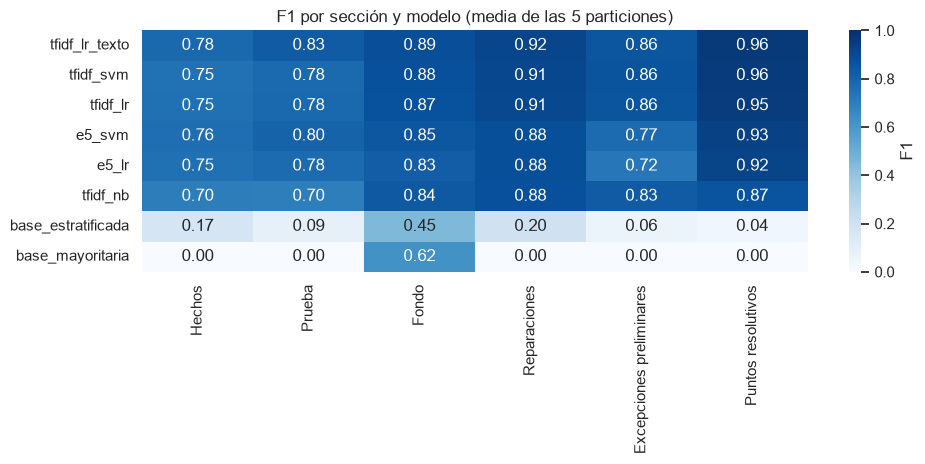

,Hechos,Prueba,Fondo,Reparaciones,Excepciones preliminares,Puntos resolutivos
modelo,,,,,,
tfidf_lr_texto,0.7822,0.8325,0.8851,0.9194,0.8552,0.9587
tfidf_svm,0.7476,0.7812,0.8758,0.9118,0.8610,0.9550
tfidf_lr,0.7530,0.7826,0.8724,0.9095,0.8573,0.9525
e5_svm,0.7595,0.8044,0.8511,0.8824,0.7735,0.9338
e5_lr,0.7519,0.7768,0.8252,0.8811,0.7228,0.9242
tfidf_nb,0.7034,0.7031,0.8411,0.8787,0.8348,0.8664
base_estratificada,0.1699,0.0872,0.4507,0.2003,0.0569,0.0353
base_mayoritaria,0.0000,0.0000,0.6213,0.0000,0.0000,0.0000


In [12]:
cols_f1 = [f"f1_{c}" for c in CLASES_SECCION]
por_clase = tabla_cv.groupby("modelo")[cols_f1].mean().rename(columns=lambda c: c.removeprefix("f1_"))
por_clase = por_clase.loc[por_clase.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.heatmap(por_clase, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "F1"})
ax.set_title("F1 por sección y modelo (media de las 5 particiones)"); ax.set_ylabel("")
guardar_fig("c23_t2_f1_por_clase")
guardar_tabla(por_clase.round(4), "t2_f1_por_clase")

### 7.2 Matriz de confusión del mejor modelo
**Qué hace esta celda.** Une las predicciones de prueba de las 5 particiones del mejor modelo (cada chunk se predice una sola vez, cuando su caso estaba en la partición de prueba) y dibuja la matriz de confusión de dos formas:
- **en conteos**, para ver el tamaño de cada error;
- **normalizada por fila**: cada fila suma 1 y muestra, entre los chunks que de verdad son de esa sección, qué porcentaje cae en cada predicción (equivale a la exhaustividad por clase en la diagonal).

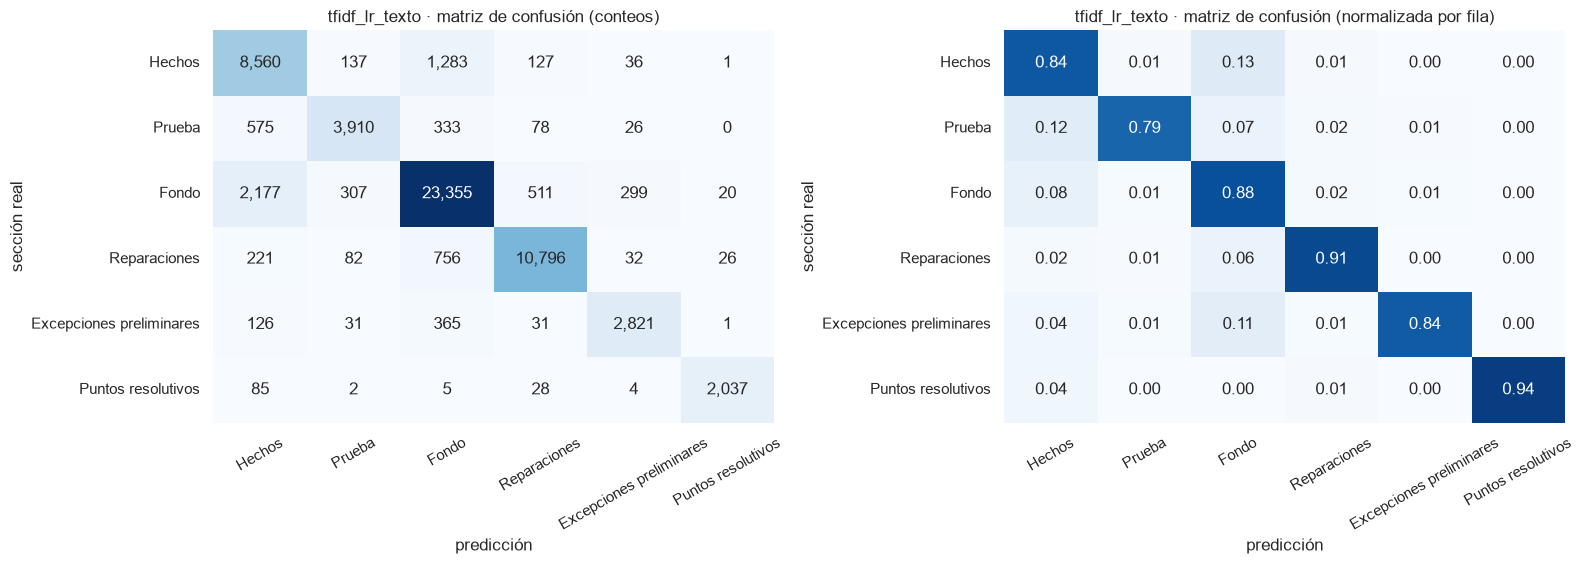

,real,predicho,chunks,% de la clase real
10,Fondo,Hechos,2177,8.2
1,Hechos,Fondo,1283,12.6
17,Reparaciones,Fondo,756,6.3
5,Prueba,Hechos,575,11.7
12,Fondo,Reparaciones,511,1.9
22,Excepciones preliminares,Fondo,365,10.8


In [13]:
pred_m = oof[mejor]; conf_m = oof_conf[mejor]
cm = confusion_matrix(y, pred_m, labels=CLASES_SECCION)
cm_n = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(16, 5.8))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", xticklabels=CLASES_SECCION, yticklabels=CLASES_SECCION, ax=ax[0], cbar=False)
sns.heatmap(cm_n, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=CLASES_SECCION, yticklabels=CLASES_SECCION, ax=ax[1], cbar=False)
for a, t in zip(ax, ["conteos", "normalizada por fila"]):
    a.set_title(f"{mejor} · matriz de confusión ({t})"); a.set_xlabel("predicción"); a.set_ylabel("sección real")
    a.tick_params(axis="x", rotation=30)
guardar_fig("c24_t2_matriz_confusion")
guardar_tabla(pd.DataFrame(cm, index=CLASES_SECCION, columns=CLASES_SECCION), "t2_matriz_confusion")

# Los pares más confundidos (fuera de la diagonal)
pares = pd.DataFrame([(a, b, cm[i, j], cm_n[i, j]) for i, a in enumerate(CLASES_SECCION) for j, b in enumerate(CLASES_SECCION) if i != j],
                     columns=["real", "predicho", "chunks", "% de la clase real"]).sort_values("chunks", ascending=False).head(6)
display(pares.assign(**{"% de la clase real": (100 * pares["% de la clase real"]).round(1)}))

### 7.3 Confusión entre Hechos y Fondo
**Por qué se mira aparte.** El análisis de la Entrega 1 mostró que Hechos y Fondo se mezclan en el espacio de embeddings: el Fondo vuelve a narrar los hechos al analizarlos. Se espera que sea el principal error. Esta parte lo cuantifica y lo explica:

1. **Tasas de error** en las dos direcciones y su concentración: ¿pocos casos concentran los errores o están repartidos?
2. **Palabras que separan las dos clases:** una regresión logística binaria Hechos vs Fondo (con TF-IDF de lemas), ajustada con todos los datos **solo para interpretar**, nunca para evaluar. Los coeficientes más altos empujan hacia Hechos y los más bajos hacia Fondo.
3. **Confianza:** si el modelo duda más cuando se equivoca, el umbral de confianza del bloque 8 tiene sentido.
4. **Ejemplos reales** de cada tipo de error para leer.

In [14]:
es_h, es_f = y == "Hechos", y == "Fondo"
h_como_f = es_h & (pred_m == "Fondo")
f_como_h = es_f & (pred_m == "Hechos")
print(f"Hechos clasificados como Fondo: {h_como_f.sum():,} de {es_h.sum():,} ({100 * h_como_f.sum() / es_h.sum():.1f} %)".replace(",", "."))
print(f"Fondo clasificados como Hechos: {f_como_h.sum():,} de {es_f.sum():,} ({100 * f_como_h.sum() / es_f.sum():.1f} %)".replace(",", "."))
tot_err = (pred_m != y).sum(); hf = h_como_f.sum() + f_como_h.sum()
print(f"Esos dos errores son el {100 * hf / tot_err:.1f} % de todos los errores del modelo ({hf:,} de {tot_err:,}).".replace(",", "."))

# 1. Concentración por caso
err_caso = pd.DataFrame({"caso": grupos, "err_hf": h_como_f | f_como_h}).groupby("caso")["err_hf"].agg(["sum", "size"])
err_caso = err_caso.sort_values("sum", ascending=False)
acum = err_caso["sum"].cumsum() / err_caso["sum"].sum()
print(f"Casos con al menos un error Hechos↔Fondo: {(err_caso['sum'] > 0).sum()} de {len(err_caso)}; "
      f"el 50 % de esos errores está en {int((acum < 0.5).sum() + 1)} casos.")

# 3. Confianza en aciertos y errores
print(f"Confianza media — aciertos: {conf_m[pred_m == y].mean():.3f} · errores: {conf_m[pred_m != y].mean():.3f} "
      f"· errores Hechos↔Fondo: {conf_m[h_como_f | f_como_h].mean():.3f}")

# 2. Palabras que separan Hechos de Fondo
m_hf = es_h | es_f
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5, sublinear_tf=True, max_features=100_000)
Xhf = vec.fit_transform(sec.loc[m_hf, "texto_normalizado"])
lr_hf = LogisticRegression(C=1, max_iter=300, class_weight="balanced").fit(Xhf, es_h[m_hf].astype(int))
terminos = np.array(vec.get_feature_names_out()); coef = lr_hf.coef_[0]
top = pd.DataFrame({"hacia Hechos": terminos[np.argsort(coef)[::-1][:15]], "peso H": np.sort(coef)[::-1][:15].round(2),
                    "hacia Fondo": terminos[np.argsort(coef)[:15]], "peso F": np.sort(coef)[:15].round(2)})
display(top)
guardar_tabla(top.set_index("hacia Hechos"), "t2_terminos_hechos_vs_fondo")

Hechos clasificados como Fondo: 1.283 de 10.144 (12.6 %)
Fondo clasificados como Hechos: 2.177 de 26.669 (8.2 %)
Esos dos errores son el 44.9 % de todos los errores del modelo (3.460 de 7.705).
Casos con al menos un error Hechos↔Fondo: 364 de 422; el 50 % de esos errores está en 64 casos.
Confianza media — aciertos: 0.894 · errores: 0.662 · errores Hechos↔Fondo: 0.685


,hacia Hechos,peso H,hacia Fondo,peso F
0,informe,4.30,corte,-11.46
1,pollo,4.10,párrs,-8.01
2,señor pollo,4.05,convención,-7.90
3,pollo rivera,3.94,derecho,-6.76
4,abril,3.92,estado,-6.60
5,solicitar,3.77,observar,-5.38
6,juzgado,3.73,tribunal,-5.18
7,emitir,3.66,sentido,-4.79
8,junio,3.60,alegar,-4.53
9,septiembre,3.51,corte observar,-4.50


,peso H,hacia Fondo,peso F
hacia Hechos,,,
informe,4.30,corte,-11.46
pollo,4.10,párrs,-8.01
señor pollo,4.05,convención,-7.90
pollo rivera,3.94,derecho,-6.76
abril,3.92,estado,-6.60
solicitar,3.77,observar,-5.38
juzgado,3.73,tribunal,-5.18
emitir,3.66,sentido,-4.79
junio,3.60,alegar,-4.53


**Ejemplos y errores según el contexto.** Dos lecturas:

- **Ejemplos de texto:** cinco chunks de Hechos que el modelo llamó Fondo y cinco al revés, con su confianza. Léanlos antes de escribir la interpretación en el artículo: es lo que permite decir *por qué* se confunden (por ejemplo, un Fondo que resume los hechos, o un Hechos que ya valora la conducta del Estado).
- **Error por época y por tamaño del chunk:** cuánto cambia la exactitud con la década de la sentencia y con la longitud del texto. Es la señal de qué tan bien se transferirá el modelo a las sentencias antiguas de «Sin sección».


HECHOS que el modelo llamó FONDO

· 883977206_sentencia_chunk_0091 (2016) · confianza 0.61
  En una audiencia privada de 22 de septiembre de 1994 ante el Fiscal Superior Militar (supra párr. 50), el señor Pollo Rivera manifestó: Preguntando cómo se entera que la policía actuó en forma violenta contra él [Blas Cori] para que no lo incriminara? Dijo: porque lo hicieron en su presencia.- Preguntando entonces lo forzaron en su presencia y no fue voluntario? Dijo: no fue voluntario.- Preguntaron a usted lo presio …

· 883975403_sentencia_chunk_0105 (2013) · confianza 0.43
  Sin embargo, los representantes y las víctimas indicaron que el cumplimiento de los acuerdos a los que se comprometió el gobierno fue parcial y que el proyecto de construcción de viviendas en dichos asentamientos, iniciado en octubre de 2000, presentó un rendimiento deficiente. Además, señalaron que el proceso de cedulación y registro de las personas que retornaron a la Cuenca se realizó parcialmente; y que "[a] pesa …


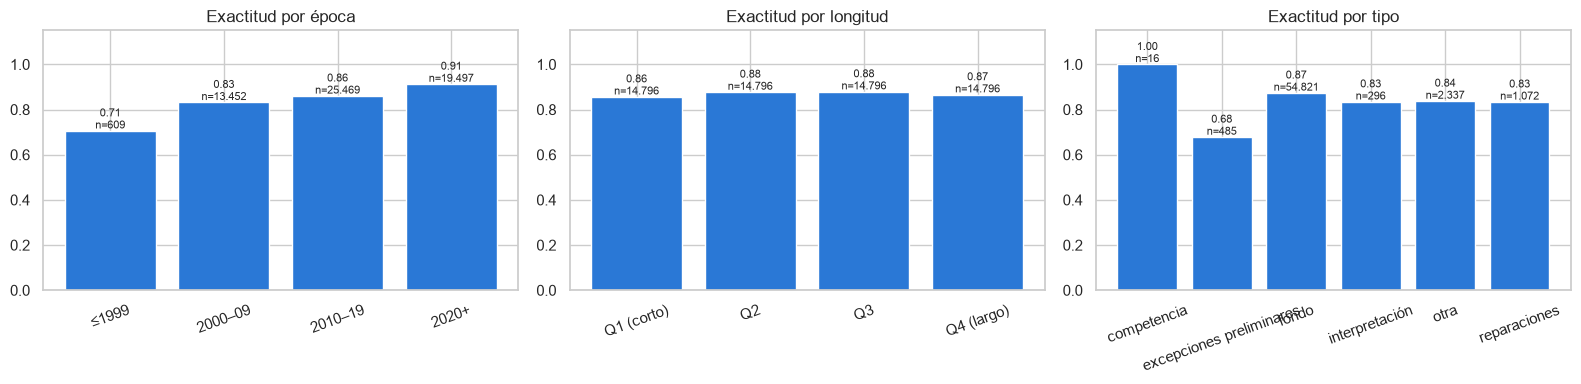

In [15]:
rng = np.random.default_rng(SEMILLA)
def mostrar(mascara, titulo, n=5):
    print("\n" + "=" * 100 + f"\n{titulo}\n" + "=" * 100)
    for i in rng.choice(np.flatnonzero(mascara), size=min(n, mascara.sum()), replace=False):
        print(f"\n· {sec['chunk_id'].iat[i]} ({sec['anio'].iat[i]:.0f}) · confianza {conf_m[i]:.2f}")
        print("  " + " ".join(sec['texto'].iat[i].split())[:420] + " …")
mostrar(h_como_f, "HECHOS que el modelo llamó FONDO")
mostrar(f_como_h, "FONDO que el modelo llamó HECHOS")

# Error por época y por longitud
ev = pd.DataFrame({"acierto": pred_m == y, "anio": sec["anio"], "palabras": sec["num_palabras"], "tipo": sec["tipo_sentencia"]})
ev["época"] = pd.cut(ev["anio"], [1985, 1999, 2009, 2019, 2030], labels=["≤1999", "2000–09", "2010–19", "2020+"])
ev["longitud"] = pd.qcut(ev["palabras"].rank(method="first"), 4, labels=["Q1 (corto)", "Q2", "Q3", "Q4 (largo)"])   # rank: evita bordes repetidos
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ["época", "longitud", "tipo"]):
    g = ev.groupby(col, observed=True)["acierto"].agg(["mean", "size"])
    a.bar(g.index.astype(str), g["mean"], color="#2a78d6")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        a.text(i, m + 0.01, f"{m:.2f}\nn={n:,}".replace(",", "."), ha="center", fontsize=8)
    a.set_ylim(0, 1.15); a.set_title(f"Exactitud por {col}"); a.tick_params(axis="x", rotation=20)
guardar_fig("c25_t2_error_por_contexto")

## 8. Aplicación a los chunks «Sin sección»

**Qué hace este bloque.** Usa el mejor modelo para asignar una sección a los 1.718 chunks «Sin sección», **solo cuando el modelo está suficientemente seguro**.

**Pasos de la celda:**
1. **Modelo final:** se reajusta `mejor` con **todos** los chunks etiquetados, eligiendo hiperparámetros con la validación interna por casos (no hay partición de prueba aquí: ya se midió en el bloque 4).
2. **Umbral de confianza:** con las predicciones fuera de muestra (OOF) del mismo modelo se calcula la precisión que se alcanza según el umbral y se toma el **menor umbral con precisión ≥ `PREC_OBJETIVO`**. La curva se calcula sobre la «época comparable», es decir, los chunks etiquetados de años hasta el percentil 95 del año de «Sin sección», porque esos chunks vienen de sentencias antiguas y el desempeño en las recientes es optimista.
3. **Predicción** y resumen: cuántos chunks pasan el umbral, cómo se reparten por sección y su confianza.
4. **Muestra para revisión manual** (`t2_revision_manual_sin_seccion.csv`): 12 chunks por sección predicha, con una columna `seccion_real` vacía. **Esta es la única forma de verificar de verdad la precisión en «Sin sección»**, porque no hay etiquetas. Quien la rellene puede calcular la precisión real con la celda siguiente.

**Límite que hay que decir en el artículo:** la curva de precisión sale de sentencias con títulos, que son más recientes y de otro estilo. La revisión manual es la evidencia directa.

Modelo final: tfidf_lr_texto · {'clf__C': 10}
Época comparable: años ≤ 2014 → 25.993 chunks etiquetados
Umbral elegido: 0.65 


,umbral,cobertura,precisión
0,0.40,0.984,0.842
1,0.45,0.963,0.850
2,0.50,0.933,0.862
3,0.55,0.895,0.876
4,0.60,0.860,0.889
5,0.65,0.823,0.901
6,0.70,0.785,0.913
7,0.75,0.746,0.923
8,0.80,0.697,0.934
9,0.85,0.638,0.946



Pasan el umbral: 1.210 de 1.718 (70.4 %)


,predichos,aceptados,confianza media
seccion_predicha,,,
Excepciones preliminares,276,195,0.790
Fondo,410,293,0.787
Hechos,426,273,0.724
Prueba,271,186,0.758
Puntos resolutivos,17,12,0.797
Reparaciones,318,251,0.822


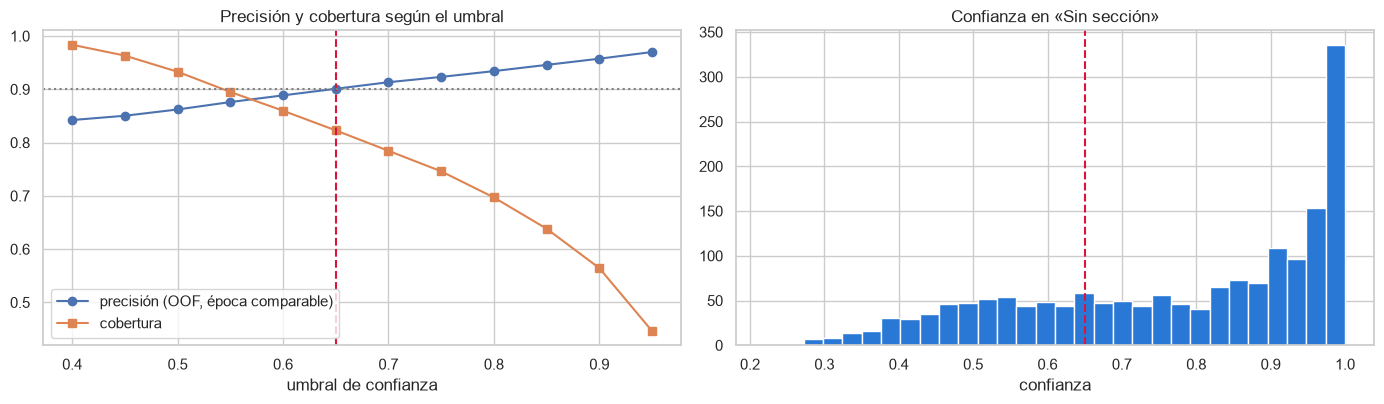

Muestra de revisión manual: 72 chunks → t2_revision_manual_sin_seccion.csv


In [16]:
spec = MODELOS[mejor]
modelo_final, p_final = ajustar(spec["construir"], spec["rejilla"], ENTRADAS[spec["entrada"]], y, grupos)
print("Modelo final:", mejor, "·", p_final)

# 2. Umbral con las predicciones OOF, en la época comparable
anio_tope = sin["anio"].quantile(0.95)
comparable = (sec["anio"] <= anio_tope).to_numpy()
if comparable.sum() < 1000:
    comparable = np.ones(len(sec), bool)
print(f"Época comparable: años ≤ {anio_tope:.0f} → {comparable.sum():,} chunks etiquetados".replace(",", "."))
ok = (pred_m == y)
curva = []
for u in np.arange(0.40, 1.0, 0.05):
    m = comparable & (conf_m >= u)
    curva.append({"umbral": round(u, 2), "cobertura": m.sum() / comparable.sum(), "precisión": ok[m].mean() if m.sum() else np.nan})
curva = pd.DataFrame(curva)
candidatos = curva[curva["precisión"] >= PREC_OBJETIVO]
UMBRAL = float(candidatos["umbral"].iloc[0]) if len(candidatos) else float(curva["umbral"].iloc[-1])
UMBRAL_CUMPLE = len(candidatos) > 0
print(f"Umbral elegido: {UMBRAL} " + ("" if UMBRAL_CUMPLE else f"(⚠ ninguno llega a {PREC_OBJETIVO}: se usa el más alto)"))
display(curva.round(3))
guardar_tabla(curva.round(4).set_index("umbral"), "t2_curva_umbral")

# 3. Predicción sobre «Sin sección»
X_sin = {"lemas": sin["texto_normalizado"], "texto": sin["texto"],
         "e5": (asegurar_embeddings(sin) if spec["entrada"] == "e5" else None)}[spec["entrada"]]
pred_sin, conf_sin = predecir(modelo_final, X_sin)
sin_pred = sin[["chunk_id", "doc_id", "caso_id", "anio", "num_palabras"]].assign(seccion_predicha=pred_sin, confianza=conf_sin,
                                                                               acepta=conf_sin >= UMBRAL)
sin_pred.to_csv(DIR_RESULTADOS / "t2_sin_seccion_predicciones.csv", index=False)
print(f"\nPasan el umbral: {sin_pred['acepta'].sum():,} de {len(sin_pred):,} ({100 * sin_pred['acepta'].mean():.1f} %)".replace(",", "."))
display(pd.DataFrame({"predichos": sin_pred["seccion_predicha"].value_counts(),
                      "aceptados": sin_pred[sin_pred["acepta"]]["seccion_predicha"].value_counts(),
                      "confianza media": sin_pred.groupby("seccion_predicha")["confianza"].mean().round(3)}).fillna(0))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(curva["umbral"], curva["precisión"], marker="o", label="precisión (OOF, época comparable)")
ax[0].plot(curva["umbral"], curva["cobertura"], marker="s", label="cobertura")
ax[0].axvline(UMBRAL, color="crimson", ls="--"); ax[0].axhline(PREC_OBJETIVO, color="gray", ls=":")
ax[0].set_xlabel("umbral de confianza"); ax[0].legend(); ax[0].set_title("Precisión y cobertura según el umbral")
ax[1].hist(conf_sin, bins=30, color="#2a78d6"); ax[1].axvline(UMBRAL, color="crimson", ls="--")
ax[1].set_title("Confianza en «Sin sección»"); ax[1].set_xlabel("confianza")
guardar_fig("c26_t2_umbral_sin_seccion")

# 4. Muestra para revisión manual
muestra = sin_pred.merge(sin[["chunk_id", "texto"]], on="chunk_id")
muestra = pd.concat([g.sample(min(12, len(g)), random_state=SEMILLA) for _, g in muestra.groupby("seccion_predicha")])
muestra = muestra.assign(texto=muestra["texto"].str.replace(r"\s+", " ", regex=True).str[:700], seccion_real="")
muestra.to_csv(DIR_RESULTADOS / "t2_revision_manual_sin_seccion.csv", index=False)
print(f"Muestra de revisión manual: {len(muestra)} chunks → t2_revision_manual_sin_seccion.csv")

**Después de la revisión manual.** Quien revise abre `t2_revision_manual_sin_seccion.csv`, escribe en `seccion_real` una de las seis secciones (o `otra` si el chunk no pertenece a ninguna, por ejemplo introducción o competencia) y vuelve a correr esta celda. Calcula la precisión real de las etiquetas del modelo, y por separado la de las que pasan el umbral.

In [17]:
ruta_rev = DIR_RESULTADOS / "t2_revision_manual_sin_seccion.csv"
rev = pd.read_csv(ruta_rev).dropna(subset=["seccion_real"])
rev = rev[rev["seccion_real"].astype(str).str.strip() != ""]
if len(rev):
    rev["acierto"] = rev["seccion_real"].str.strip() == rev["seccion_predicha"]
    print(f"Revisados: {len(rev)} · precisión de todas las predicciones: {rev['acierto'].mean():.2f}")
    if rev["acepta"].any():
        print(f"Precisión de las que pasan el umbral (n={int(rev['acepta'].sum())}): {rev.loc[rev['acepta'], 'acierto'].mean():.2f}")
    display(rev.groupby("seccion_predicha")["acierto"].agg(["mean", "size"]).round(2))
else:
    print("Aún no hay filas con 'seccion_real' rellena en", ruta_rev.name)

Aún no hay filas con 'seccion_real' rellena en t2_revision_manual_sin_seccion.csv


## 9. ¿Mejora el filtro por sección de `buscar()`?

**La pregunta.** `buscar(..., seccion="Hechos")` solo admite los chunks cuya `seccion_canonica` es esa. Si se **añaden** a cada sección los chunks «Sin sección» que el clasificador asignó con confianza suficiente, ¿el filtro recupera más resultados relevantes?

**Cómo se mide, con las consultas juzgadas de la Entrega 1:**
- **Consultas:** las 20 consultas propias (conjunto B, juicios por chunk) y las 182 de los Cuadernillos (conjunto C, juicios por párrafo, que aquí se llevan al chunk que lo contiene).
- **Filtro de cada consulta:** la sección más frecuente entre sus chunks relevantes (los de «Sin sección» no cuentan). Simula a quien sabe en qué sección está lo que busca. Las consultas sin chunks relevantes en alguna de las seis secciones se omiten.
- **Dos universos:** **original** (como en la Entrega 1) y **nuevo** (original + «Sin sección» reasignados con confianza ≥ umbral).
- **Recuperación:** solo **densa**, con los embeddings de la Entrega 1 (`embeddings.npy`, que son los que usa `buscar()`) y e5 para la consulta. El filtro solo cambia qué chunks son elegibles, así que el efecto no depende del método. No se diversifica por caso.
- **Métricas:** nDCG@10 (ganancia lineal 0/1/2) y Recall@10, con la diferencia pareada por consulta y su intervalo del 95 % por bootstrap (1.000 remuestreos, semilla 42). Se reporta también el **subconjunto de consultas afectadas**, que son las que tienen al menos un chunk relevante en «Sin sección» reasignado, porque en las demás no puede haber cambio.

**Limitaciones que hay que decir:** (1) los juicios de B los hizo un modelo de lenguaje y los de C son incompletos (solo los párrafos que el Cuadernillo cita); (2) la sección que se usa de filtro sale de los juicios, así que mide el potencial del filtro, no una búsqueda real de usuario; (3) con pocas consultas afectadas los intervalos son anchos; (4) la precisión de las etiquetas asignadas en «Sin sección» solo se sabe con la revisión manual.

Esta celda necesita `chunks.parquet` y `embeddings.npy` de la Entrega 1 (`procesado/caracteristicas/`) y los CSV de `evaluacion/` del repositorio. Si falta algo, se omite el bloque.

In [18]:
EVAL_DIR = DIR_REPO / "evaluacion"
ruta_ch  = BASE_DIR / "procesado/caracteristicas/chunks.parquet"
ruta_e1  = BASE_DIR / "procesado/caracteristicas/embeddings.npy"
requisitos = [ruta_ch, ruta_e1, EVAL_DIR / "qrels_consultas_propias.csv", EVAL_DIR / "qrels_cuadernillos.csv"]
HAY_BUSQUEDA = all(r.exists() for r in requisitos)
print("Archivos necesarios:", {r.name: r.exists() for r in requisitos})

Archivos necesarios: {'chunks.parquet': True, 'embeddings.npy': True, 'qrels_consultas_propias.csv': True, 'qrels_cuadernillos.csv': True}


In [19]:
if HAY_BUSQUEDA:
    ch = pd.read_parquet(ruta_ch, columns=["chunk_id", "doc_id", "parte", "parr_ini", "parr_fin", "seccion_canonica"])
    idx_chunk = pd.Series(np.arange(len(ch)), index=ch["chunk_id"])
    E1 = np.load(ruta_e1, mmap_mode="r")
    assert len(E1) == len(ch), "embeddings.npy y chunks.parquet no tienen el mismo orden/tamaño"

    # Sección original y sección nueva (original + «Sin sección» reasignados con confianza ≥ umbral)
    sec_orig = ch["seccion_canonica"].to_numpy(dtype=object)
    sec_nueva = sec_orig.copy()
    acep = sin_pred[sin_pred["acepta"]]
    pos_acep = idx_chunk.reindex(acep["chunk_id"]).to_numpy()
    assert not np.isnan(pos_acep).any(), "hay chunks de «Sin sección» que no están en chunks.parquet"
    sec_nueva[pos_acep.astype(int)] = acep["seccion_predicha"].to_numpy()
    reasignados = set(pos_acep.astype(int))
    print(f"Chunks reasignados: {len(reasignados):,} de {(sec_orig == 'Sin sección').sum():,} «Sin sección» del índice".replace(",", "."))

    # ── Consultas y juicios, llevados a índices de chunk con ganancia 0/1/2 ──
    cp = pd.read_csv(EVAL_DIR / "consultas_propias.csv"); qp = pd.read_csv(EVAL_DIR / "qrels_consultas_propias.csv")
    cc = pd.read_csv(EVAL_DIR / "consultas_cuadernillos.csv"); qc = pd.read_csv(EVAL_DIR / "qrels_cuadernillos.csv")

    juicios = {}   # (conjunto, consulta_id) -> {índice de chunk: ganancia}
    for r in qp[qp["relevancia"] > 0].itertuples():
        if r.chunk_id in idx_chunk.index:
            juicios.setdefault(("B", r.consulta_id), {})[int(idx_chunk[r.chunk_id])] = int(r.relevancia)
    cuerpo = ch[ch["parte"].eq("cuerpo") & ch["parr_ini"].notna()]
    por_doc = {d: g for d, g in cuerpo.groupby("doc_id")}
    for r in qc.itertuples():
        g = por_doc.get(r.doc_id)
        if g is None:
            continue
        for i in g.index[(g["parr_ini"] <= r.num_parrafo) & (g["parr_fin"] >= r.num_parrafo)]:
            d = juicios.setdefault(("C", r.consulta_id), {})
            d[int(i)] = max(d.get(int(i), 0), int(r.relevancia))     # el chunk hereda el grado máximo

    textos_q = {("B", r.consulta_id): r.consulta for r in cp.itertuples()} | {("C", r.consulta_id): r.consulta for r in cc.itertuples()}
    claves = [k for k in textos_q if k in juicios]
    print(f"Consultas con juicios: B {sum(k[0] == 'B' for k in claves)} · C {sum(k[0] == 'C' for k in claves)}")

Chunks reasignados: 1.210 de 2.048 «Sin sección» del índice


Consultas con juicios: B 20 · C 182


**Embeddings de las consultas (con caché).** `embeddings_consultas()` codifica cada consulta con el prefijo `query: ` de e5 y guarda el resultado en `embeddings_consultas_e5.npz`. Así, en una máquina sin GPU o sin el modelo se reutiliza lo calculado en Colab. Son pocas consultas (≈ 200): en CPU toma un par de minutos.

In [20]:
RUTA_QE = DIR_DATOS / "embeddings_consultas_e5.npz"

def embeddings_consultas(textos):
    # Devuelve (len(textos), 768) con prefijo «query: »; calcula solo las que faltan en el caché.
    cache = {}
    if RUTA_QE.exists():
        z = np.load(RUTA_QE); cache = dict(zip(z["textos"].tolist(), z["emb"]))
    falta = [t for t in dict.fromkeys(textos) if t not in cache]
    if falta:
        modelo = cargar_e5()
        nuevo = modelo.encode([f"query: {t}" for t in falta], batch_size=32, normalize_embeddings=True, convert_to_numpy=True)
        cache.update(zip(falta, nuevo.astype(np.float32)))
        np.savez(RUTA_QE, textos=np.array(list(cache), dtype=str), emb=np.stack(list(cache.values())))
    return np.stack([cache[t] for t in textos]).astype(np.float32)

if HAY_BUSQUEDA:
    Q = embeddings_consultas([textos_q[k] for k in claves])
    print("Consultas codificadas:", Q.shape)

W1116 23:03:13.814000 31844 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


e5 cargado en cuda


Consultas codificadas: (202, 768)


**Evaluación.** Para cada consulta:
1. se calcula la similitud coseno con todos los chunks (producto punto, porque los vectores están normalizados);
2. se escoge la sección de filtro;
3. se ordenan solo los chunks elegibles, con el universo original y con el nuevo;
4. se miden nDCG@10 y Recall@10 y si algún relevante pertenece a un chunk reasignado.

El nDCG ideal se calcula con todos los chunks relevantes del corpus, igual para los dos universos, así que las dos cifras son comparables entre sí.

In [21]:
def top_k(puntaje, mascara, k=10):
    p = np.where(mascara, puntaje, -np.inf)
    cand = np.argpartition(-p, min(k, len(p) - 1))[:k]
    cand = cand[np.argsort(-p[cand])]
    return cand[np.isfinite(p[cand])]

def ndcg_recall(ranking, gan, k=10):
    dcg = sum(gan.get(int(i), 0) / np.log2(pos + 2) for pos, i in enumerate(ranking[:k]))
    ideal = sum(g / np.log2(pos + 2) for pos, g in enumerate(sorted(gan.values(), reverse=True)[:k]))
    rec = sum(1 for i in ranking[:k] if gan.get(int(i), 0) > 0) / len(gan)
    return (dcg / ideal if ideal else 0.0), rec

filas_busq = []
if HAY_BUSQUEDA:
    Etodo = np.asarray(E1, dtype=np.float32)
    S = Etodo @ Q.T                                         # (chunks × consultas)
    for j, k in enumerate(claves):
        gan = juicios[k]
        secs_rel = pd.Series([sec_orig[i] for i in gan]).loc[lambda s: s.isin(CLASES_SECCION)]
        if secs_rel.empty:
            continue                                        # sin chunk relevante en una de las seis secciones
        objetivo = secs_rel.value_counts().index[0]
        m_orig, m_nueva = sec_orig == objetivo, sec_nueva == objetivo
        r_o, r_n = top_k(S[:, j], m_orig), top_k(S[:, j], m_nueva)
        (nd_o, rc_o), (nd_n, rc_n) = ndcg_recall(r_o, gan), ndcg_recall(r_n, gan)
        filas_busq.append({"conjunto": k[0], "consulta": k[1], "seccion_filtro": objetivo,
                           "elegibles_orig": int(m_orig.sum()), "elegibles_nuevo": int(m_nueva.sum()),
                           "relevantes_reasignados": sum(i in reasignados for i in gan if m_nueva[i] and not m_orig[i]),
                           "ndcg_orig": nd_o, "ndcg_nuevo": nd_n, "recall_orig": rc_o, "recall_nuevo": rc_n})
    busq = pd.DataFrame(filas_busq)
    busq.to_csv(DIR_RESULTADOS / "t2_buscar_por_consulta.csv", index=False)
    print(f"Consultas evaluadas: {len(busq)} (B {int((busq['conjunto'] == 'B').sum())}, C {int((busq['conjunto'] == 'C').sum())}) "
          f"· afectadas: {int((busq['relevantes_reasignados'] > 0).sum())}")
else:
    print("Se omite: faltan archivos de la Entrega 1 (ver la celda anterior).")

Consultas evaluadas: 199 (B 20, C 179) · afectadas: 23


**Resumen con intervalos.** Para cada conjunto y para el total, se reporta la media de cada métrica con el universo original y con el nuevo, la diferencia pareada y su intervalo bootstrap. Se repite en el subconjunto de consultas afectadas.

**Cómo leerlo:**
- Una diferencia positiva con el intervalo por encima de 0 es evidencia de que reasignar mejora el filtro.
- Una diferencia cercana a 0 en todas las consultas pero positiva en las **afectadas** quiere decir que el efecto es real pero se diluye, porque la mayoría de las consultas no tienen contenido en «Sin sección».
- Si el nDCG baja en las afectadas, hay etiquetas erróneas que meten ruido en el filtro: sube el umbral.

In [22]:
def boot_diff(a, b, n=1000, semilla=SEMILLA):
    d = np.asarray(b) - np.asarray(a); rng = np.random.default_rng(semilla)
    medias = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)]
    return d.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5)

if HAY_BUSQUEDA and len(busq):
    grupos_eval = {"B (consultas propias)": busq["conjunto"] == "B", "C (Cuadernillos)": busq["conjunto"] == "C", "B + C": busq["conjunto"].notna()}
    salida = []
    for nombre_g, m_g in grupos_eval.items():
        for sub, m_s in [("todas", m_g), ("afectadas", m_g & (busq["relevantes_reasignados"] > 0))]:
            b = busq[m_s]
            if len(b) < 2:
                salida.append({"conjunto": nombre_g, "consultas": sub, "n": len(b)}); continue
            fila = {"conjunto": nombre_g, "consultas": sub, "n": len(b),
                    "elegibles orig → nuevo": f"{b['elegibles_orig'].mean():,.0f} → {b['elegibles_nuevo'].mean():,.0f}".replace(",", ".")}
            for met in ["ndcg", "recall"]:
                d, lo, hi = boot_diff(b[f"{met}_orig"], b[f"{met}_nuevo"])
                fila[f"{met}@10 orig"] = round(b[f"{met}_orig"].mean(), 3); fila[f"{met}@10 nuevo"] = round(b[f"{met}_nuevo"].mean(), 3)
                fila[f"Δ{met}"] = f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]"
            salida.append(fila)
    resumen_busq = pd.DataFrame(salida)
    guardar_tabla(resumen_busq.set_index("conjunto"), "t2_buscar_resumen")
    display(resumen_busq)

,conjunto,consultas,n,elegibles orig → nuevo,ndcg@10 orig,ndcg@10 nuevo,Δndcg,recall@10 orig,recall@10 nuevo,Δrecall
0,B (consultas propias),todas,20,24.906 → 25.194,0.791,0.791,"+0.000 [+0.000, +0.000]",0.400,0.400,"+0.000 [+0.000, +0.000]"
1,B (consultas propias),afectadas,2,27.216 → 27.509,0.794,0.794,"+0.000 [+0.000, +0.000]",0.362,0.362,"+0.000 [+0.000, +0.000]"
2,C (Cuadernillos),todas,179,23.086 → 23.367,0.141,0.141,"-0.000 [-0.000, +0.000]",0.128,0.128,"+0.000 [+0.000, +0.000]"
3,C (Cuadernillos),afectadas,21,25.130 → 25.417,0.033,0.033,"+0.000 [+0.000, +0.000]",0.023,0.023,"+0.000 [+0.000, +0.000]"
4,B + C,todas,199,23.269 → 23.550,0.207,0.207,"-0.000 [-0.000, +0.000]",0.156,0.156,"+0.000 [+0.000, +0.000]"
5,B + C,afectadas,23,25.311 → 25.599,0.099,0.099,"+0.000 [+0.000, +0.000]",0.052,0.052,"+0.000 [+0.000, +0.000]"


## 10. Salidas: repositorio y artículo

**Qué hace esta celda.**
1. **No toca el repositorio.** Las tablas quedan en `procesado/clasificacion/resultados/` (Drive o carpeta local). Para versionar las pequeñas, se copian a mano (ver `clasificacion/README.md`); el notebook no ejecuta git ni copia archivos al repositorio.
2. **Escribe `t2_borrador_articulo.md`** con la metodología de esta tarea (descrita según lo que de verdad hace el notebook) y las tablas de resultados ya rellenas con las cifras de esta ejecución. **La interpretación queda para ustedes**: léanla con las figuras y los ejemplos del bloque 7 antes de redactar las conclusiones; el borrador no las inventa.

**Tablas del artículo:** la 1 (modelos), la 2 (F1 por clase), la 3 (prueba temporal) y la 4 (efecto en `buscar()`, si se corrió el bloque 9).

In [23]:
def md_tabla(df, dec=3):
    try:
        return df.round(dec).to_markdown()
    except ImportError:                       # sin tabulate: texto plano
        return "```\n" + df.round(dec).to_string() + "\n```"

n_chunks, n_casos = len(sec), sec["caso_id"].nunique()
umbral_txt = f"{UMBRAL:.2f}".replace(".", ",") + (f", umbral con el que la precisión fuera de muestra alcanza {PREC_OBJETIVO:.0%} en las sentencias de época comparable" if UMBRAL_CUMPLE else " (ningún umbral alcanzó la precisión objetivo; se usó el más alto)")
n_chunks_t, n_sin_t = f"{len(sec):,}".replace(",", "."), f"{len(sin):,}".replace(",", ".")
t1 = tabla_cv.groupby("modelo")[["exactitud", "f1_macro", "f1_ponderado"]].agg(["mean", "std"]).round(3)
t1.columns = [f"{a} ({'media' if b == 'mean' else 'desv.'})" for a, b in t1.columns]
t1 = t1.sort_values("f1_macro (media)", ascending=False)

texto = f'''# Tarea 2 · Sección de cada fragmento (borrador para el artículo)

> Generado por `t2_secciones.ipynb`{" en MODO_PRUEBA: NO USAR ESTAS CIFRAS" if MODO_PRUEBA else ""}. Revisar y redactar la interpretación.

## Metodología

**Tarea.** Clasificación multiclase de la sección de cada fragmento de sentencia en seis clases: {", ".join(CLASES_SECCION)}.

**Datos.** {n_chunks_t} fragmentos de {n_casos} casos, de las sentencias de la Corte IDH procesadas en la Entrega 1 (fragmentos de hasta 250 palabras, que no mezclan secciones). Se excluyeron los fragmentos casi duplicados de otro caso (similitud coseno de embeddings ≥ 0,97) y los de menos de 20 palabras. La etiqueta es la sección canónica obtenida de los títulos del PDF. La entrada del clasificador es el texto del fragmento **sin la cabecera de contexto**, porque la cabecera incluye el nombre de la sección.

**Particiones.** Validación cruzada de {N_PARTICIONES} particiones estratificadas por clase y **agrupadas por caso** (`StratifiedGroupKFold`, semilla {SEMILLA}), de modo que un caso nunca aparece a la vez en entrenamiento y prueba. Las particiones son las mismas para todo el equipo. Se comprobó además con una prueba temporal: entrenamiento con sentencias hasta {ANIO_CORTE} y prueba con las posteriores, sin los casos presentes en ambos lados.

**Representaciones y modelos.** (i) TF-IDF de unigramas y bigramas sobre los lemas del fragmento (`min_df`=3, `max_df`=0,5, tf sublineal, hasta 100.000 características) y, como ablación, sobre el texto sin lematizar; (ii) embeddings `multilingual-e5-base` recalculados sin cabecera (prefijo `passage:`, ventana de 512 tokens, normalizados). Clasificadores: línea base (clase mayoritaria y azar según la frecuencia de clase), Complement Naive Bayes, regresión logística y SVM lineal sobre TF-IDF, y regresión logística y SVM lineal sobre e5{"; además, RoBERTa-BNE afinado (lr 2e-5, " + str(EPOCAS) + " épocas, ventana de " + str(MAX_LEN) + " tokens, época elegida con el 10 % de casos del entrenamiento)" if AFINAR_ROBERTA else ""}.

**Validación anidada.** Los hiperparámetros se eligen dentro del entrenamiento de cada partición, con una validación interna de {N_INTERNO} particiones agrupadas por caso y F1 macro como criterio. El vocabulario y los pesos IDF se reajustan en cada entrenamiento (van dentro del `Pipeline`). Los modelos con regresión logística y SVM usan pesos de clase balanceados.

**Métricas.** F1 macro (principal, por el desbalance de clases), exactitud, exactitud balanceada y F1 ponderado; F1 por clase; matriz de confusión. Se reporta la media y la desviación estándar entre particiones.

**Aplicación a «Sin sección».** El mejor modelo ({mejor}) se reajustó con todos los fragmentos etiquetados y se aplicó a {n_sin_t} fragmentos sin sección. Solo se acepta la etiqueta si la confianza es al menos {umbral_txt}. El efecto en el filtro por sección de `buscar()` se midió con las consultas juzgadas de la Entrega 1 (nDCG@10 y Recall@10 de la búsqueda densa, con y sin los fragmentos reasignados; diferencia pareada con intervalo bootstrap del 95 %).

## Resultados

### Tabla 1. Modelos (validación cruzada por casos)
{md_tabla(t1)}

### Tabla 2. F1 por sección (media de las particiones)
{md_tabla(por_clase)}

### Tabla 3. Prueba temporal (F1 macro)
{md_tabla(comp)}

### Matriz de confusión del mejor modelo ({mejor})
{md_tabla(pd.DataFrame(cm, index=CLASES_SECCION, columns=CLASES_SECCION), 0)}

Hechos clasificados como Fondo: {100 * h_como_f.sum() / es_h.sum():.1f} %. Fondo clasificados como Hechos: {100 * f_como_h.sum() / es_f.sum():.1f} %. Entre los dos, el {100 * hf / tot_err:.1f} % de todos los errores.

### «Sin sección»
Aceptados con confianza ≥ {UMBRAL:.2f}: {int(sin_pred["acepta"].sum())} de {len(sin_pred)} ({100 * sin_pred["acepta"].mean():.1f} %).

{"### Tabla 4. Efecto en el filtro de buscar()" + chr(10) + md_tabla(resumen_busq, 3) if HAY_BUSQUEDA and len(filas_busq) else "_El bloque 9 no se ejecutó._"}

## Interpretación (completar)
- ¿Qué modelo gana y por cuánto frente a la línea base y entre sí (considerar la desviación entre particiones)?
- ¿Aporta e5 sobre TF-IDF? ¿Ayuda la lematización (`tfidf_lr` frente a `tfidf_lr_texto`)?
- ¿Por qué se confunden Hechos y Fondo? (ver términos y ejemplos del bloque 7.3)
- ¿El modelo se transfiere a sentencias posteriores a {ANIO_CORTE}? ¿Y a las antiguas de «Sin sección»? (revisión manual)
- ¿El filtro de `buscar()` mejora? ¿En cuántas consultas?
'''
(DIR_RESULTADOS / "t2_borrador_articulo.md").write_text(texto, encoding="utf-8")
print(f"Borrador escrito en {DIR_RESULTADOS / 't2_borrador_articulo.md'}")

Borrador escrito en C:\Users\USER\Desktop\proyectoPLN\procesado\clasificacion\resultados\t2_borrador_articulo.md
